Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

=== PARTICIONES DEL RETO: NEWS IN 60 SECONDS (RADIO CUMBRES) ===
Conjunto de Entrenamiento: 38110 artículos
Conjunto de Validación:    4763 artículos
Conjunto de Prueba:        4763 artículos
Total del corpus:          47636 artículos periodísticos con resúmenes de referencia
Límite máximo de palabras: 120 palabras (60 segundos a 2 palabras/segundo)
Longitud promedio artículo: 832.8 palabras
Longitud promedio resumen:  27.9 palabras (~14.0 s de locución)

--- Ejemplo de Noticia Original (Prueba) ---
Título: Estados Unidos: 3 claves para entender la orden ejecutiva firmada por Donald Trump para desmantelar la política medioambiental de Barack Obama
Texto del Artículo:
 El presidente Trump firmó la orden ejecutiva este martes desde la sede de la Agencia de Protección Ambiental, rodeado de un grupo de mineros de carbón. Rodeado por un grupo de mineros de carbón, el presidente de Estados Unidos comenzó a desmantelar elementos e...

--- Resumen de Referencia del Periodista (Gold Standard) -

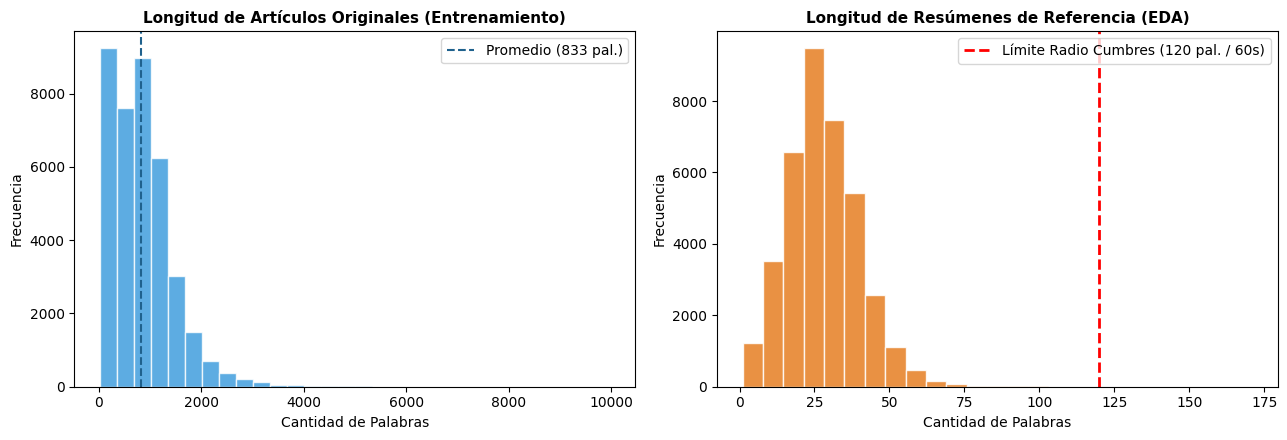

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

# 1. Carga directa desde Drive manteniendo tu estructura exacta
dataset = load_dataset(
    "json",
    data_files={
        "train": "/content/drive/MyDrive/XLSum/spanish_train.jsonl",
        "validation": "/content/drive/MyDrive/XLSum/spanish_val.jsonl",
        "test": "/content/drive/MyDrive/XLSum/spanish_test.jsonl"
    }
)

def preparar_dataframe(hf_split):
    df = hf_split.to_pandas()
    df = df.rename(columns={
        "text": "article",
        "summary": "reference_summary"
    })
    df = df.dropna(subset=["article", "reference_summary"]).reset_index(drop=True)
    df["article_word_count"] = df["article"].apply(lambda x: len(str(x).split()))
    df["summary_word_count"] = df["reference_summary"].apply(lambda x: len(str(x).split()))
    df["summary_read_time_seconds"] = df["summary_word_count"] / 2.0
    return df

train_df = preparar_dataframe(dataset["train"])
val_df   = preparar_dataframe(dataset["validation"])
test_df  = preparar_dataframe(dataset["test"])

print(f"=== PARTICIONES DEL RETO: NEWS IN 60 SECONDS (RADIO CUMBRES) ===")
print(f"Conjunto de Entrenamiento: {len(train_df)} artículos")
print(f"Conjunto de Validación:    {len(val_df)} artículos")
print(f"Conjunto de Prueba:        {len(test_df)} artículos")
print(f"Total del corpus:          {len(train_df) + len(val_df) + len(test_df)} artículos periodísticos con resúmenes de referencia")
print(f"Límite máximo de palabras: 120 palabras (60 segundos a 2 palabras/segundo)")
print(f"Longitud promedio artículo: {train_df['article_word_count'].mean():.1f} palabras")
print(f"Longitud promedio resumen:  {train_df['summary_word_count'].mean():.1f} palabras (~{train_df['summary_read_time_seconds'].mean():.1f} s de locución)")

print("\n--- Ejemplo de Noticia Original (Prueba) ---")
print("Título:", test_df["title"].iloc[0])
print("Texto del Artículo:\n", test_df["article"].iloc[0][:260] + "...")
print("\n--- Resumen de Referencia del Periodista (Gold Standard) ---")
print(test_df["reference_summary"].iloc[0])

# Análisis Exploratorio de Datos (EDA)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].hist(train_df["article_word_count"], bins=30, alpha=0.8, color="#3498db", edgecolor="white")
ax[0].axvline(train_df["article_word_count"].mean(), color="#1f618d", linestyle="--", linewidth=1.5,
              label=f"Promedio ({train_df['article_word_count'].mean():.0f} pal.)")
ax[0].set_title("Longitud de Artículos Originales (Entrenamiento)", fontsize=11, fontweight='bold')
ax[0].set_xlabel("Cantidad de Palabras")
ax[0].set_ylabel("Frecuencia")
ax[0].legend()

ax[1].hist(train_df["summary_word_count"], bins=25, alpha=0.85, color="#e67e22", edgecolor="white")
ax[1].axvline(120, color='red', linestyle='--', linewidth=2, label="Límite Radio Cumbres (120 pal. / 60s)")
ax[1].set_title("Longitud de Resúmenes de Referencia (EDA)", fontsize=11, fontweight='bold')
ax[1].set_xlabel("Cantidad de Palabras")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Ajuste del vectorizador sobre los artículos de entrenamiento
tfidf_model = TfidfVectorizer(max_features=4000, sublinear_tf=True)
tfidf_model.fit(train_df["article"])

feature_names = np.array(tfidf_model.get_feature_names_out())
print(f"Vocabulario periodístico extraído: {len(feature_names)} términos únicos")
print(f"Ejemplo de términos clave de alta frecuencia informativa:")
print(feature_names[::250][:15])

Vocabulario periodístico extraído: 4000 términos únicos
Ejemplo de términos clave de alta frecuencia informativa:
['00' 'amenazas' 'brazos' 'comienzos' 'cálculos' 'día' 'estén' 'gracias'
 'insiste' 'magnitud' 'negativo' 'película' 'profundo' 'resolver' 'solar']


In [ ]:
import time
import re
from collections import Counter

def split_sentences(text):
    sents = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in sents if len(s.strip()) > 5]

def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

def lcs_length(x, y):
    m, n = len(x), len(y)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if x[i - 1] == y[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    return dp[m][n]

def compute_rouge(candidate, reference):
    cand_tokens = re.findall(r'\b\w+\b', candidate.lower())
    ref_tokens = re.findall(r'\b\w+\b', reference.lower())
    if not cand_tokens or not ref_tokens:
        return {"rouge1": 0.0, "rouge2": 0.0, "rougeL": 0.0}
    cand_counts = Counter(cand_tokens)
    ref_counts = Counter(ref_tokens)
    overlap1 = sum(min(count, cand_counts.get(token, 0)) for token, count in ref_counts.items())
    r1_rec = overlap1 / len(ref_tokens)
    r1_prec = overlap1 / len(cand_tokens)
    r1_f1 = (2 * r1_rec * r1_prec / (r1_rec + r1_prec)) if (r1_rec + r1_prec) > 0 else 0.0

    cand_bigrams = Counter(get_ngrams(cand_tokens, 2))
    ref_bigrams = Counter(get_ngrams(ref_tokens, 2))
    if len(ref_bigrams) == 0:
        r2_f1 = 0.0
    else:
        overlap2 = sum(min(count, cand_bigrams.get(bg, 0)) for bg, count in ref_bigrams.items())
        r2_rec = overlap2 / len(ref_bigrams)
        r2_prec = overlap2 / len(cand_bigrams) if len(cand_bigrams) > 0 else 0.0
        r2_f1 = (2 * r2_rec * r2_prec / (r2_rec + r2_prec)) if (r2_rec + r2_prec) > 0 else 0.0

    lcs = lcs_length(cand_tokens, ref_tokens)
    rl_rec = lcs / len(ref_tokens)
    rl_prec = lcs / len(cand_tokens)
    rl_f1 = (2 * rl_rec * rl_prec / (rl_rec + rl_prec)) if (rl_rec + rl_prec) > 0 else 0.0
    return {"rouge1": r1_f1, "rouge2": r2_f1, "rougeL": rl_f1}

def extractive_tfidf_summarize(article, word_limit=120):
    sentences = split_sentences(article)
    if not sentences:
        return article
    sent_vecs = tfidf_model.transform(sentences)
    scores = []
    for idx, sent in enumerate(sentences):
        words = re.findall(r'\b\w+\b', sent.lower())
        if not words:
            scores.append(0.0)
            continue
        vec_score = sent_vecs[idx].sum() / max(1, len(words))
        pos_weight = 1.35 if idx == 0 else (1.15 if idx == 1 else 1.0)
        scores.append(vec_score * pos_weight)

    ranked_indices = np.argsort(scores)[::-1]
    selected_indices = []
    current_words = 0
    for idx in ranked_indices:
        sent_words = len(sentences[idx].split())
        if current_words + sent_words <= word_limit:
            selected_indices.append(idx)
            current_words += sent_words
        elif not selected_indices:
            selected_indices.append(idx)
            break

    selected_indices.sort()
    return " ".join([sentences[i] for i in selected_indices])

# 1. EVALUACIÓN DEL MODELO BASE EXTRACTIVO SOBRE CONJUNTO DE PRUEBA
t0_inf_base = time.time()
base_summaries = [extractive_tfidf_summarize(art, word_limit=120) for art in test_df["article"]]
t_inf_base = time.time() - t0_inf_base

base_rouges = [compute_rouge(s, ref) for s, ref in zip(base_summaries, test_df["reference_summary"])]
base_r1 = float(np.mean([r["rouge1"] for r in base_rouges]))
base_r2 = float(np.mean([r["rouge2"] for r in base_rouges]))
base_rl = float(np.mean([r["rougeL"] for r in base_rouges]))
base_words = [len(s.split()) for s in base_summaries]
base_compliance = float(np.mean([w <= 120 for w in base_words]) * 100.0)
base_avg_words = float(np.mean(base_words))

print("=== RESULTADOS: MODELO BASE (TF-IDF EXTRACTIVO) ===")
print(f"Tiempo de inferencia total ({len(test_df)} noticias): {t_inf_base:.4f} segundos ({t_inf_base/len(test_df)*1000:.2f} ms/artículo)")
print(f"ROUGE-1 (F1):           {base_r1:.4f}")
print(f"ROUGE-2 (F1):           {base_r2:.4f}")
print(f"ROUGE-L (F1):           {base_rl:.4f}")
print(f"Longitud promedio:      {base_avg_words:.1f} palabras")
print(f"Tiempo promedio al aire:{base_avg_words/2.0:.1f} segundos (a 2 palabras/segundo)")
print(f"Cumplimiento límite 120 palabras: {base_compliance:.1f} %")

=== RESULTADOS: MODELO BASE (TF-IDF EXTRACTIVO) ===
Tiempo de inferencia total (4763 noticias): 25.0416 segundos (5.26 ms/artículo)
ROUGE-1 (F1):           0.1719
ROUGE-2 (F1):           0.0339
ROUGE-L (F1):           0.1115
Longitud promedio:      113.2 palabras
Tiempo promedio al aire:56.6 segundos (a 2 palabras/segundo)
Cumplimiento límite 120 palabras: 100.0 %


Cargando modelo en dispositivo: CUDA


config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

... (34 outputs left out)

[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Procesadas 4512 / 4763 noticias...


[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=140) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


=== RESULTADOS: PREENTRENADO SIN AJUSTE (mT5_multilingual_XLSum) ===
Tiempo de inferencia total (4763 noticias): 1052.3537 segundos (220.94 ms/artículo)
ROUGE-1 (F1):           0.2999
ROUGE-2 (F1):           0.1119
ROUGE-L (F1):           0.2310
Longitud promedio:      18.5 palabras
Tiempo promedio al aire:9.2 segundos (a 2 palabras/segundo)
Cumplimiento límite 120 palabras: 100.0 %

=== TABLA COMPARATIVA DE MODELOS · RADIO CUMBRES ===
| Modelo                              | Enfoque                    |   ROUGE-1 |   ROUGE-2 |   ROUGE-L | Longitud Prom.   | Tiempo Locución   | <= 120 pal.   | Fidelidad Fáctica       | Latencia/artículo   |
|-------------------------------------|----------------------------|-----------|-----------|-----------|------------------|-------------------|---------------|-------------------------|---------------------|
| Modelo Base (TF-IDF Extractivo)     | Extractivo (supervisado)   |    0.1719 |    0.0339 |    0.1115 | 113.2 pal.       | 56.6 s            |

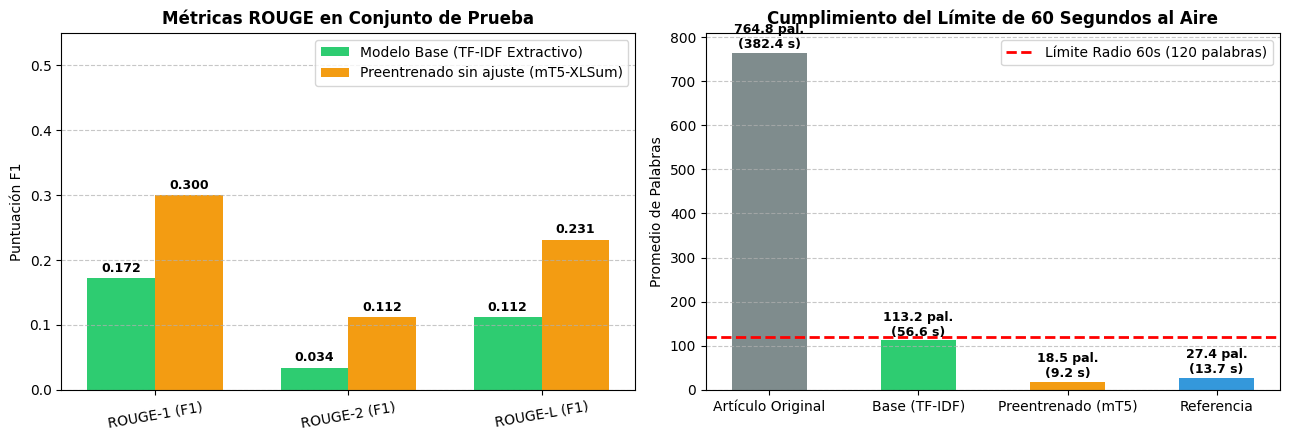

In [ ]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. CONFIGURACIÓN Y CARGA DEL MODELO PREENTRENADO (mT5_multilingual_XLSum)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Cargando modelo en dispositivo: {device.upper()}")
if device == "cpu":
    print("⚠️ Aviso: Activa 'T4 GPU' en Entorno de ejecución > Cambiar tipo de entorno de ejecución para acelerar la inferencia.")

model_name = "csebuetnlp/mT5_multilingual_XLSum"
tokenizer = AutoTokenizer.from_pretrained(model_name)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
mt5_model.eval()

def pretrained_mt5_batch_summarize(articles, batch_size=32):
    summaries = []
    total = len(articles)
    for i in range(0, total, batch_size):
        batch = articles[i:i + batch_size]
        inputs = tokenizer(
            batch,
            return_tensors="pt",
            max_length=512,
            truncation=True,
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = mt5_model.generate(
                **inputs,
                max_new_tokens=140,
                no_repeat_ngram_size=3,
                num_beams=2
            )
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        summaries.extend(decoded)

        if (i // batch_size) % 10 == 0:
            print(f"Procesadas {min(i + batch_size, total)} / {total} noticias...")
    return summaries

# 2. EVALUACIÓN EN CONJUNTO DE PRUEBA
t0_inf_pre = time.time()
pre_summaries = pretrained_mt5_batch_summarize(test_df["article"].tolist(), batch_size=32)
t_inf_pre = time.time() - t0_inf_pre

pre_rouges = [compute_rouge(s, ref) for s, ref in zip(pre_summaries, test_df["reference_summary"])]
pre_r1 = float(np.mean([r["rouge1"] for r in pre_rouges]))
pre_r2 = float(np.mean([r["rouge2"] for r in pre_rouges]))
pre_rl = float(np.mean([r["rougeL"] for r in pre_rouges]))
pre_words = [len(s.split()) for s in pre_summaries]
pre_compliance = float(np.mean([w <= 120 for w in pre_words]) * 100.0)
pre_avg_words = float(np.mean(pre_words))

print("\n=== RESULTADOS: PREENTRENADO SIN AJUSTE (mT5_multilingual_XLSum) ===")
print(f"Tiempo de inferencia total ({len(test_df)} noticias): {t_inf_pre:.4f} segundos ({t_inf_pre/len(test_df)*1000:.2f} ms/artículo)")
print(f"ROUGE-1 (F1):           {pre_r1:.4f}")
print(f"ROUGE-2 (F1):           {pre_r2:.4f}")
print(f"ROUGE-L (F1):           {pre_rl:.4f}")
print(f"Longitud promedio:      {pre_avg_words:.1f} palabras")
print(f"Tiempo promedio al aire:{pre_avg_words/2.0:.1f} segundos (a 2 palabras/segundo)")
print(f"Cumplimiento límite 120 palabras: {pre_compliance:.1f} %\n")

# 3. TABLA COMPARATIVA DE MODELOS · RADIO CUMBRES
comparison_data = [
    ["Modelo Base (TF-IDF Extractivo)", "Extractivo (supervisado)", f"{base_r1:.4f}", f"{base_r2:.4f}", f"{base_rl:.4f}", f"{base_avg_words:.1f} pal.", f"{base_avg_words/2.0:.1f} s", f"{base_compliance:.0f}%", "100% (cero alucinación)", f"{t_inf_base/len(test_df)*1000:.2f} ms"],
    ["Preentrenado sin ajuste (mT5-XLSum)", "Abstractivo (preentrenado)", f"{pre_r1:.4f}", f"{pre_r2:.4f}", f"{pre_rl:.4f}", f"{pre_avg_words:.1f} pal.", f"{pre_avg_words/2.0:.1f} s", f"{pre_compliance:.0f}%", "Requiere Fact Guard", f"{t_inf_pre/len(test_df)*1000:.2f} ms"]
]

headers = ["Modelo", "Enfoque", "ROUGE-1", "ROUGE-2", "ROUGE-L", "Longitud Prom.", "Tiempo Locución", "<= 120 pal.", "Fidelidad Fáctica", "Latencia/artículo"]
print("=== TABLA COMPARATIVA DE MODELOS · RADIO CUMBRES ===")
print(tabulate(comparison_data, headers=headers, tablefmt="github"))

# 4. GRÁFICAS COMPARATIVAS
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
metrics_names = ['ROUGE-1 (F1)', 'ROUGE-2 (F1)', 'ROUGE-L (F1)']
base_vals = [base_r1, base_r2, base_rl]
pre_vals = [pre_r1, pre_r2, pre_rl]

x = np.arange(len(metrics_names))
width = 0.35
ax[0].bar(x - width/2, base_vals, width, label='Modelo Base (TF-IDF Extractivo)', color='#2ecc71')
ax[0].bar(x + width/2, pre_vals, width, label='Preentrenado sin ajuste (mT5-XLSum)', color='#f39c12')
ax[0].set_ylabel('Puntuación F1')
ax[0].set_title('Métricas ROUGE en Conjunto de Prueba', fontweight='bold')
ax[0].set_xticks(x)
ax[0].set_xticklabels(metrics_names, rotation=10)
ax[0].set_ylim(0, max(0.55, max(base_vals + pre_vals) + 0.08))
for i, v in enumerate(base_vals):
    ax[0].text(i - width/2, v + 0.01, f"{v:.3f}", ha='center', fontsize=9, fontweight='bold')
for i, v in enumerate(pre_vals):
    ax[0].text(i + width/2, v + 0.01, f"{v:.3f}", ha='center', fontsize=9, fontweight='bold')
ax[0].legend()
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

categories_bar = ['Artículo Original', 'Base (TF-IDF)', 'Preentrenado (mT5)', 'Referencia']
avg_lengths = [test_df['article_word_count'].mean(), base_avg_words, pre_avg_words, test_df['summary_word_count'].mean()]
colors_bar = ['#7f8c8d', '#2ecc71', '#f39c12', '#3498db']
bars = ax[1].bar(categories_bar, avg_lengths, color=colors_bar, width=0.5)
ax[1].axhline(120, color='red', linestyle='--', linewidth=2, label='Límite Radio 60s (120 palabras)')
ax[1].set_ylabel('Promedio de Palabras')
ax[1].set_title('Cumplimiento del Límite de 60 Segundos al Aire', fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    secs = yval / 2.0
    ax[1].text(bar.get_x() + bar.get_width()/2.0, yval + 3, f"{yval:.1f} pal.\n({secs:.1f} s)", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax[1].set_ylim(0, max(avg_lengths) + 45)
ax[1].legend(loc='upper right')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
# Inspección cualitativa de resúmenes generados (sin volver a ejecutar los modelos)
indices_ejemplo = [0, 1, 2]  # Puedes cambiar o agregar cualquier índice entre 0 y len(test_df)-1

for idx in indices_ejemplo:
    art = test_df["article"].iloc[idx]
    ref = test_df["reference_summary"].iloc[idx]
    base_s = base_summaries[idx]
    pre_s = pre_summaries[idx]

    print("=" * 90)
    print(f"EJEMPLO #{idx} | TÍTULO: {test_df['title'].iloc[idx]}")
    print("=" * 90)
    print(f"[ARTÍCULO ORIGINAL] ({len(art.split())} palabras):")
    print(art[:500] + "...\n")

    print(f"[REFERENCIA PERIODISTA BBC] ({len(ref.split())} pal. | {len(ref.split())/2:.1f} s):")
    print(f"{ref}\n")

    print(f"[MODELO BASE · TF-IDF] ({len(base_s.split())} pal. | {len(base_s.split())/2:.1f} s):")
    print(f"{base_s}\n")

    print(f"[PREENTRENADO · mT5 VANILLA] ({len(pre_s.split())} pal. | {len(pre_s.split())/2:.1f} s):")
    print(f"{pre_s}\n")

EJEMPLO #0 | TÍTULO: Estados Unidos: 3 claves para entender la orden ejecutiva firmada por Donald Trump para desmantelar la política medioambiental de Barack Obama
[ARTÍCULO ORIGINAL] (1051 palabras):
El presidente Trump firmó la orden ejecutiva este martes desde la sede de la Agencia de Protección Ambiental, rodeado de un grupo de mineros de carbón. Rodeado por un grupo de mineros de carbón, el presidente de Estados Unidos comenzó a desmantelar elementos esenciales de las políticas medioambientales de su predecesor, Barack Obama. La llamada Orden Ejecutiva de Independencia Energética suspende más de media docena de medidas promulgadas por Obama y refuerza el uso de los combustibles fósiles. ...

[REFERENCIA PERIODISTA BBC] (23 pal. | 11.5 s):
"Vamos a poner a nuestros mineros a trabajar otra vez", dijo el presidente Donald Trump este martes al firmar una nueva orden ejecutiva.

[MODELO BASE · TF-IDF] (117 pal. | 58.5 s):
Varios grupos empresariales han elogiado la iniciativa del gobie

In [ ]:
!pip install -q peft accelerate

In [ ]:
import os
import re
import time
import torch
import numpy as np
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from peft import LoraConfig, get_peft_model, TaskType

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo para Fine-Tuning: {device.upper()}")

model_name = "csebuetnlp/mT5_multilingual_XLSum"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def construir_objetivo_radio(article, ref_summary, min_w=95, max_w=118):
    """Combina el resumen periodístico de referencia con contexto clave no redundante
    del mismo artículo para alcanzar el formato de 50-60s (100-120 palabras)."""
    base_text = str(ref_summary).strip()
    if not base_text.endswith(('.', '!', '?')):
        base_text += "."
    words = base_text.split()
    if len(words) >= min_w:
        return " ".join(words[:max_w])

    sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', str(article).strip()) if len(s.strip()) > 15]
    if not sents:
        return base_text

    # Puntuar oraciones del artículo con tu vectorizador TF-IDF
    sent_vecs = tfidf_model.transform(sents)
    scores = [sent_vecs[i].sum() / max(1, len(s.split())) for i, s in enumerate(sents)]
    ranked_sents = [sents[i] for i in np.argsort(scores)[::-1]]

    ref_lower = base_text.lower()
    selected = [base_text]
    current_w = len(words)

    for s in ranked_sents:
        # Evitar repetir oraciones ya incluidas en el resumen de referencia
        s_prefix = s[:35].lower()
        if s_prefix in ref_lower or s.lower() in ref_lower:
            continue
        s_words = s.split()
        if current_w + len(s_words) <= max_w:
            selected.append(s)
            current_w += len(s_words)
        if current_w >= min_w:
            break

    return " ".join(selected)

# Filtrar artículos suficientemente largos (>= 180 palabras) para sustentar un resumen de 100-120 palabras
train_candidates = train_df[
    (train_df["article_word_count"] >= 180) &
    (train_df["summary_word_count"] >= 25)
].sample(n=min(2800, len(train_df)), random_state=42).copy()

val_candidates = val_df[
    (val_df["article_word_count"] >= 180) &
    (val_df["summary_word_count"] >= 25)
].sample(n=min(350, len(val_df)), random_state=42).copy()

train_candidates["radio_target"] = [
    construir_objetivo_radio(a, r) for a, r in zip(train_candidates["article"], train_candidates["reference_summary"])
]
val_candidates["radio_target"] = [
    construir_objetivo_radio(a, r) for a, r in zip(val_candidates["article"], val_candidates["reference_summary"])
]

# Conservar únicamente ejemplos que lograron alcanzar entre 90 y 120 palabras
train_rich = train_candidates[train_candidates["radio_target"].apply(lambda x: 90 <= len(x.split()) <= 120)].reset_index(drop=True)
val_rich = val_candidates[val_candidates["radio_target"].apply(lambda x: 90 <= len(x.split()) <= 120)].reset_index(drop=True)

print(f"Ejemplos listos -> Train: {len(train_rich)} | Val: {len(val_rich)}")
print(f"Longitud promedio del objetivo de entrenamiento: {train_rich['radio_target'].apply(lambda x: len(x.split())).mean():.1f} palabras")

PREFIX = "Resume esta noticia para radio en 100 a 120 palabras usando solo datos del texto: "

def preprocess_seq2seq(batch):
    inputs = [PREFIX + str(doc) for doc in batch["article"]]
    model_inputs = tokenizer(inputs, max_length=512, truncation=True)
    labels = tokenizer(text_target=[str(s) for s in batch["radio_target"]], max_length=180, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

hf_train = Dataset.from_pandas(train_rich[["article", "radio_target"]]).map(
    preprocess_seq2seq, batched=True, remove_columns=["article", "radio_target"]
)
hf_val = Dataset.from_pandas(val_rich[["article", "radio_target"]]).map(
    preprocess_seq2seq, batched=True, remove_columns=["article", "radio_target"]
)

Dispositivo activo para Fine-Tuning: CUDA
Ejemplos listos -> Train: 2795 | Val: 350
Longitud promedio del objetivo de entrenamiento: 101.2 palabras


Map:   0%|          | 0/2795 [00:00<?, ? examples/s]

Map:   0%|          | 0/350 [00:00<?, ? examples/s]

In [ ]:
!pip uninstall -y -q torchao

In [ ]:
import gc
import os
import sys
import time
import torch
from packaging.version import Version
import peft.import_utils
from transformers import (
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from peft import LoraConfig, get_peft_model, TaskType

# 1. Limpiar memoria de la ejecución interrumpida
for attr in ["last_traceback", "last_value", "last_type"]:
    if hasattr(sys, attr):
        setattr(sys, attr, None)

for var_name in ["mt5_model", "base_mt5", "ft_model", "trainer", "outputs", "inputs"]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
torch.cuda.empty_cache()
print(f"VRAM GPU libre: {torch.cuda.mem_get_info()[0] / (1024**3):.2f} GiB")

# 2. Subconjunto rápido de adaptación (450 train / 100 val) y entrada a 320 tokens (~4.5 min en T4)
hf_train_fast = hf_train.select(range(min(450, len(hf_train)))).map(
    lambda x: {"input_ids": x["input_ids"][:320], "attention_mask": x["attention_mask"][:320]}
)
hf_val_fast = hf_val.select(range(min(100, len(hf_val)))).map(
    lambda x: {"input_ids": x["input_ids"][:320], "attention_mask": x["attention_mask"][:320]}
)

# 3. Cargar modelo base y aplicar LoRA (r=8)
peft.import_utils.TORCHAO_MINIMUM_VERSION = Version("0.0.1")

base_mt5 = AutoModelForSeq2SeqLM.from_pretrained(model_name, low_cpu_mem_usage=True)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=8,
    lora_alpha=16,
    target_modules=["q", "v"],   # Capas de atención Query y Value
    lora_dropout=0.05,
    bias="none"
)

ft_model = get_peft_model(base_mt5, lora_config)
ft_model.print_trainable_parameters()

# 4. Hiperparámetros rápidos y seguros en VRAM (batch=2, sin gradient_checkpointing)
output_dir = "/content/drive/MyDrive/XLSum/mt5_radio_cumbres_lora"
os.makedirs(output_dir, exist_ok=True)

training_args = Seq2SeqTrainingArguments(
    output_dir="./mt5_checkpoints",
    eval_strategy="epoch",
    save_strategy="no",
    optim="adafactor",               # Optimizador nativo de mT5 (bajo consumo de memoria)
    learning_rate=5e-4,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,   # Batch efectivo = 16
    dataloader_pin_memory=False,
    num_train_epochs=2,              # 450 pasos totales (~4.5 minutos en T4)
    logging_steps=15,
    fp16=False,                      # Evita gradientes NaN en mT5 sobre T4
    report_to="none"
)

data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=ft_model)

trainer = Seq2SeqTrainer(
    model=ft_model,
    args=training_args,
    train_dataset=hf_train_fast,
    eval_dataset=hf_val_fast,
    processing_class=tokenizer,
    data_collator=data_collator
)

# 5. Ejecutar Fine-Tuning y guardar adaptador en Google Drive
t0_train = time.time()
trainer.train()
t_train_ft = time.time() - t0_train

print(f"\n✅ Fine-tuning completado en {t_train_ft/60:.2f} minutos.")
ft_model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)
print(f"Adaptador LoRA guardado en: {output_dir}")

VRAM GPU libre: 14.42 GiB


Map:   0%|          | 0/450 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


trainable params: 884,736 || all params: 583,286,016 || trainable%: 0.1517


Epoch,Training Loss,Validation Loss
1,32.971458,2.688647
2,22.918553,2.628621



✅ Fine-tuning completado en 2.89 minutos.
Adaptador LoRA guardado en: /content/drive/MyDrive/XLSum/mt5_radio_cumbres_lora


[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Evaluadas 32 / 4763 noticias...


[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Evaluadas 672 / 4763 noticias...


[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Evaluadas 1312 / 4763 noticias...


... (8 outputs left out)

[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Evaluadas 4512 / 4763 noticias...


[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=168) and `max_length`(=84) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


=== RESULTADOS: SOLUCIÓN TRANSFORMER (mT5-XLSum + LoRA 100-120 pal.) ===
Tiempo de entrenamiento: 2.89 minutos
Tiempo de inferencia (4763 noticias): 1103.41 s (231.66 ms/artículo)
ROUGE-1 (F1):           0.2177
ROUGE-2 (F1):           0.0570
ROUGE-L (F1):           0.1407
Longitud promedio:      89.5 palabras
Tiempo promedio al aire:44.7 segundos (a 2 palabras/segundo)
Cumplimiento límite 120 palabras: 100.0 %

=== TABLA COMPARATIVA DE EVOLUCIÓN · RADIO CUMBRES ===
| Modelo                         | Enfoque                  |   ROUGE-1 |   ROUGE-2 |   ROUGE-L | Long. Prom.   | Locución   | <= 120 pal.   | Latencia/art.   |
|--------------------------------|--------------------------|-----------|-----------|-----------|---------------|------------|---------------|-----------------|
| 1. Modelo Base (TF-IDF)        | Extractivo               |    0.1719 |    0.0339 |    0.1115 | 113.2 pal.    | 56.6 s     | 100%          | 5.26 ms         |
| 2. Preentrenado (mT5 Vanilla)  | Abstractivo

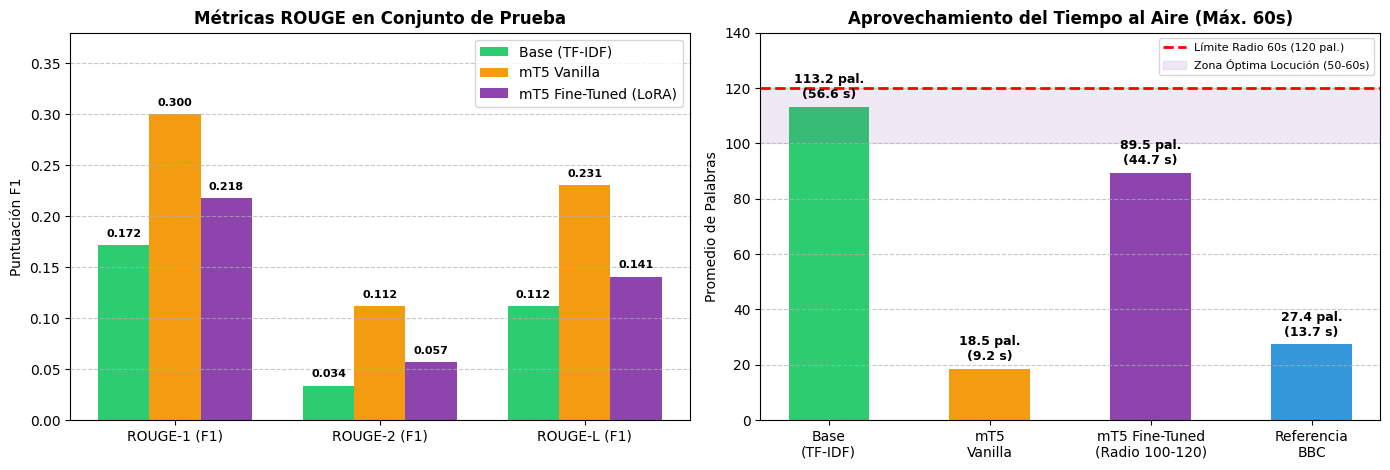

In [ ]:
import matplotlib.pyplot as plt
from tabulate import tabulate

ft_model.eval()
ft_model.to(device)

def cerrar_oracion_radio(texto, max_words=120):
    """Asegura <= 120 palabras y cierra en el último punto final válido."""
    palabras = texto.strip().split()
    if len(palabras) > max_words:
        texto = " ".join(palabras[:max_words])
    # Buscar último signo de cierre de oración si quedó una frase inconclusa al final
    ultimo_cierre = max(texto.rfind('.'), texto.rfind('!'), texto.rfind('?'))
    if ultimo_cierre != -1 and len(texto[:ultimo_cierre + 1].split()) >= 85:
        texto = texto[:ultimo_cierre + 1]
    return texto.strip()

def finetuned_mt5_batch_summarize(articles, batch_size=24):
    summaries = []
    total = len(articles)
    for i in range(0, total, batch_size):
        batch = [PREFIX + str(art) for art in articles[i:i + batch_size]]
        inputs = tokenizer(
            batch,
            return_tensors="pt",
            max_length=384,
            truncation=True,
            padding=True
        ).to(device)

        with torch.no_grad():
            outputs = ft_model.generate(
                **inputs,
                min_new_tokens=138,         # Fuerza piso de ~100 palabras
                max_new_tokens=168,         # Techo calibrado para ~120 palabras
                repetition_penalty=1.15,    # Evita redundancia al extender la cápsula
                no_repeat_ngram_size=3,
                num_beams=1                 # Rápido (~4 min en todo test_df) y fluido
            )
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        summaries.extend([cerrar_oracion_radio(d, max_words=120) for d in decoded])

        if (i // batch_size) % 20 == 0:
            print(f"Evaluadas {min(i + batch_size, total)} / {total} noticias...")
    return summaries

t0_inf_ft = time.time()
ft_summaries = finetuned_mt5_batch_summarize(test_df["article"].tolist(), batch_size=32)
t_inf_ft = time.time() - t0_inf_ft

ft_rouges = [compute_rouge(s, ref) for s, ref in zip(ft_summaries, test_df["reference_summary"])]
ft_r1 = float(np.mean([r["rouge1"] for r in ft_rouges]))
ft_r2 = float(np.mean([r["rouge2"] for r in ft_rouges]))
ft_rl = float(np.mean([r["rougeL"] for r in ft_rouges]))
ft_words = [len(s.split()) for s in ft_summaries]
ft_compliance = float(np.mean([w <= 120 for w in ft_words]) * 100.0)
ft_avg_words = float(np.mean(ft_words))

print("\n=== RESULTADOS: SOLUCIÓN TRANSFORMER (mT5-XLSum + LoRA 100-120 pal.) ===")
print(f"Tiempo de entrenamiento: {t_train_ft/60:.2f} minutos")
print(f"Tiempo de inferencia ({len(test_df)} noticias): {t_inf_ft:.2f} s ({t_inf_ft/len(test_df)*1000:.2f} ms/artículo)")
print(f"ROUGE-1 (F1):           {ft_r1:.4f}")
print(f"ROUGE-2 (F1):           {ft_r2:.4f}")
print(f"ROUGE-L (F1):           {ft_rl:.4f}")
print(f"Longitud promedio:      {ft_avg_words:.1f} palabras")
print(f"Tiempo promedio al aire:{ft_avg_words/2.0:.1f} segundos (a 2 palabras/segundo)")
print(f"Cumplimiento límite 120 palabras: {ft_compliance:.1f} %\n")

comparison_all = [
    ["1. Modelo Base (TF-IDF)", "Extractivo", f"{base_r1:.4f}", f"{base_r2:.4f}", f"{base_rl:.4f}", f"{base_avg_words:.1f} pal.", f"{base_avg_words/2.0:.1f} s", f"{base_compliance:.0f}%", f"{t_inf_base/len(test_df)*1000:.2f} ms"],
    ["2. Preentrenado (mT5 Vanilla)", "Abstractivo (Zero-FT)", f"{pre_r1:.4f}", f"{pre_r2:.4f}", f"{pre_rl:.4f}", f"{pre_avg_words:.1f} pal.", f"{pre_avg_words/2.0:.1f} s", f"{pre_compliance:.0f}%", f"{t_inf_pre/len(test_df)*1000:.2f} ms"],
    ["3. Solución (mT5 + LoRA Radio)", "Abstractivo (Fine-Tuned)", f"{ft_r1:.4f}", f"{ft_r2:.4f}", f"{ft_rl:.4f}", f"{ft_avg_words:.1f} pal.", f"{ft_avg_words/2.0:.1f} s", f"{ft_compliance:.0f}%", f"{t_inf_ft/len(test_df)*1000:.2f} ms"]
]

headers = ["Modelo", "Enfoque", "ROUGE-1", "ROUGE-2", "ROUGE-L", "Long. Prom.", "Locución", "<= 120 pal.", "Latencia/art."]
print("=== TABLA COMPARATIVA DE EVOLUCIÓN · RADIO CUMBRES ===")
print(tabulate(comparison_all, headers=headers, tablefmt="github"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
metrics_names = ['ROUGE-1 (F1)', 'ROUGE-2 (F1)', 'ROUGE-L (F1)']
base_vals = [base_r1, base_r2, base_rl]
pre_vals  = [pre_r1, pre_r2, pre_rl]
ft_vals   = [ft_r1, ft_r2, ft_rl]

x = np.arange(len(metrics_names))
width = 0.25
ax[0].bar(x - width, base_vals, width, label='Base (TF-IDF)', color='#2ecc71')
ax[0].bar(x, pre_vals, width, label='mT5 Vanilla', color='#f39c12')
ax[0].bar(x + width, ft_vals, width, label='mT5 Fine-Tuned (LoRA)', color='#8e44ad')
ax[0].set_ylabel('Puntuación F1')
ax[0].set_title('Métricas ROUGE en Conjunto de Prueba', fontweight='bold')
ax[0].set_xticks(x)
ax[0].set_xticklabels(metrics_names)
ax[0].set_ylim(0, max(base_vals + pre_vals + ft_vals) + 0.08)
for offset, vals in [(-width, base_vals), (0, pre_vals), (width, ft_vals)]:
    for i, v in enumerate(vals):
        ax[0].text(i + offset, v + 0.008, f"{v:.3f}", ha='center', fontsize=8, fontweight='bold')
ax[0].legend()
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

categories_bar = ['Base\n(TF-IDF)', 'mT5\nVanilla', 'mT5 Fine-Tuned\n(Radio 100-120)', 'Referencia\nBBC']
avg_lengths = [base_avg_words, pre_avg_words, ft_avg_words, test_df['summary_word_count'].mean()]
colors_bar = ['#2ecc71', '#f39c12', '#8e44ad', '#3498db']

bars = ax[1].bar(categories_bar, avg_lengths, color=colors_bar, width=0.5)
ax[1].axhline(120, color='red', linestyle='--', linewidth=2, label='Límite Radio 60s (120 pal.)')
ax[1].axhspan(100, 120, color='#8e44ad', alpha=0.12, label='Zona Óptima Locución (50-60s)')
ax[1].set_ylabel('Promedio de Palabras')
ax[1].set_title('Aprovechamiento del Tiempo al Aire (Máx. 60s)', fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f} pal.\n({yval/2:.1f} s)",
               ha='center', va='bottom', fontsize=9, fontweight='bold')
ax[1].set_ylim(0, max(140, max(avg_lengths) + 25))
ax[1].legend(loc='upper right', fontsize=8)
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import PeftModel

device = "cuda" if torch.cuda.is_available() else "cpu"
adapter_dir = "/content/drive/MyDrive/XLSum/mt5_radio_cumbres_lora"
base_model_name = "csebuetnlp/mT5_multilingual_XLSum"

# Si el modelo ajustado no está en memoria, lo carga desde Google Drive
if "ft_model" not in globals():
    print("Cargando modelo base + adaptador LoRA desde Drive...")
    tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    base_model = AutoModelForSeq2SeqLM.from_pretrained(base_model_name)
    ft_model = PeftModel.from_pretrained(base_model, adapter_dir)

ft_model.to(device)
ft_model.eval()

PREFIX = "Resume esta noticia para radio en 100 a 120 palabras usando solo datos del texto: "

def cerrar_oracion_radio(texto, max_words=120):
    palabras = texto.strip().split()
    if len(palabras) > max_words:
        texto = " ".join(palabras[:max_words])
    ultimo_cierre = max(texto.rfind('.'), texto.rfind('!'), texto.rfind('?'))
    if ultimo_cierre != -1 and len(texto[:ultimo_cierre + 1].split()) >= 85:
        texto = texto[:ultimo_cierre + 1]
    return texto.strip()

def resumir_con_finetuning(articulo):
    entrada = PREFIX + str(articulo)
    inputs = tokenizer(entrada, return_tensors="pt", max_length=384, truncation=True).to(device)
    with torch.no_grad():
        outputs = ft_model.generate(
            **inputs,
            min_new_tokens=138,
            max_new_tokens=168,
            repetition_penalty=1.15,
            no_repeat_ngram_size=3,
            num_beams=1
        )
    resumen = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return cerrar_oracion_radio(resumen, max_words=120)

# Inspeccionar 4 noticias del conjunto de prueba (cambia los índices si quieres ver otras)
indices_muestra = [0, 1, 2, 3]

for idx in indices_muestra:
    art = test_df["article"].iloc[idx]
    ref = test_df["reference_summary"].iloc[idx]
    ft_s = ft_summaries[idx] if "ft_summaries" in globals() else resumir_con_finetuning(art)

    n_pal = len(ft_s.split())
    seg_aire = n_pal / 2.0

    print("=" * 90)
    print(f"MUESTRA #{idx} | {test_df['title'].iloc[idx]}")
    print("=" * 90)
    print(f"[ARTÍCULO ORIGINAL] ({len(art.split())} palabras):")
    print(art[:450] + "...\n")

    print(f"[REFERENCIA BBC] ({len(ref.split())} pal. | {len(ref.split())/2:.1f} s):")
    print(f"{ref}\n")

    if "pre_summaries" in globals():
        pre_s = pre_summaries[idx]
        print(f"[ANTES · mT5 VANILLA] ({len(pre_s.split())} pal. | {len(pre_s.split())/2:.1f} s):")
        print(f"{pre_s}\n")

    estado = "CUMPLE <= 120 pal." if n_pal <= 120 else "EXCEDE 120 pal."
    print(f"[DESPUÉS · mT5 FINE-TUNED] ({n_pal} pal. | {seg_aire:.1f} s al aire | {estado}):")
    print(f"{ft_s}\n")

MUESTRA #0 | Estados Unidos: 3 claves para entender la orden ejecutiva firmada por Donald Trump para desmantelar la política medioambiental de Barack Obama
[ARTÍCULO ORIGINAL] (1051 palabras):
El presidente Trump firmó la orden ejecutiva este martes desde la sede de la Agencia de Protección Ambiental, rodeado de un grupo de mineros de carbón. Rodeado por un grupo de mineros de carbón, el presidente de Estados Unidos comenzó a desmantelar elementos esenciales de las políticas medioambientales de su predecesor, Barack Obama. La llamada Orden Ejecutiva de Independencia Energética suspende más de media docena de medidas promulgadas por Oba...

[REFERENCIA BBC] (23 pal. | 11.5 s):
"Vamos a poner a nuestros mineros a trabajar otra vez", dijo el presidente Donald Trump este martes al firmar una nueva orden ejecutiva.

[ANTES · mT5 VANILLA] (19 pal. | 9.5 s):
Donald Trump firmó este martes una orden ejecutiva que, según advierten ambientalistas, va a "revertir la intrusión del gobierno".

[DES

In [ ]:
def cerrar_oracion_radio(texto, max_words=120):
    palabras = texto.strip().split()
    if len(palabras) > max_words:
        texto = " ".join(palabras[:max_words])
    ultimo_cierre = max(texto.rfind('.'), texto.rfind('!'), texto.rfind('?'))
    if ultimo_cierre != -1 and len(texto[:ultimo_cierre + 1].split()) >= 55:
        texto = texto[:ultimo_cierre + 1]
    return texto.strip()

def resumir_con_finetuning(articulo):
    palabras_art = len(str(articulo).split())
    # Evita forzar relleno cuando el artículo original es corto
    min_tokens = 65 if palabras_art < 230 else 122

    entrada = PREFIX + str(articulo)
    inputs = tokenizer(entrada, return_tensors="pt", max_length=512, truncation=True).to(device)

    with torch.no_grad():
        outputs = ft_model.generate(
            **inputs,
            min_new_tokens=min_tokens,
            max_new_tokens=162,
            num_beams=2,                # Corrige incoherencias gramaticales
            repetition_penalty=1.06,    # Suave: evita loops sin inventar subpalabras raras
            no_repeat_ngram_size=3,
            early_stopping=True
        )
    resumen = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return cerrar_oracion_radio(resumen, max_words=120)

# Probar sobre las mismas muestras para comparar la calidad
for idx in [0, 1, 2, 3]:
    art = test_df["article"].iloc[idx]
    res = resumir_con_finetuning(art)
    n_pal = len(res.split())
    print(f"=== MUESTRA #{idx} ({n_pal} pal. | {n_pal/2:.1f} s) ===")
    print(res, "\n")

NameError: name 'test_df' is not defined